# The capacity hump: how the speed of a secondary cone sets its tonnage, its power and its product

**Question:** At what eccentric speed does the reference secondary cone move the most tonnes per hour, and what does moving away from that speed cost in power and in product size?

- **Level:** 1, Fundamentals
- **Prerequisites:** notebook 01 of topic 03-breakage-and-classification
- **Reading time:** about 30 minutes

## Objectives

By the end of this notebook you can:

- write the reduced capacity law of the engine and say what its speed factor does;
- find the speed of maximum capacity of each machine type and show that all of them share one normalised curve;
- run the engine over a range of speeds and read throughput, power and product size together;
- read the nip angle against its grip limit and say what a wider setting does to it.

## Setup

Numpy and matplotlib. The capacity and nip functions come straight from the engine's capacity module.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The cell imports the capacity law, the optimum speed, the nip geometry and the machine table, next to the engine.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from dataclasses import replace

from pipeline.model.crusher import Operating, evaluate
from pipeline.model.crusher.capacity import CAP, throughput, optimal_speed, nip_angle, nip_limit
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Data

The reference secondary cone S01 (CSS 32 mm, throw 30 mm, 360 rpm). Owner: this repository, https://github.com/fsantibanezleal/CAOS_ChancaDEM. Licence class: MIT; the committed artifacts are written by the pipeline from the parameters of each case. File read: `data/derived/manifests/S01.json`, block `params`.

The cell reads the operating point.

In [2]:
# Read the S01 operating point
op = Operating(**json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))["params"])
print(op)

Operating(machine='cone-sec', css_mm=32.0, throw_mm=30.0, speed_rpm=360.0, feed_x63_mm=90.0, feed_m=1.2, ore_axb=55.0, ore_wi=14.0, calibrated=False)


## Method

**Step 1, the law.** The engine uses a reduced form of the Evertsson cone-crusher flow model (Evertsson, 2000; https://research.chalmers.se/en/publication/759), with absolute numbers that are illustrative references per machine:

$$Q = Q_{ref}\;\frac{CSS + T/2}{g_{ref}}\;s\,e^{1-s}, \qquad s = \frac{\text{speed}}{\text{speed}_{opt}}$$

The first factor is the discharge opening, the mean gap $CSS + T/2$ over a reference gap, so capacity grows linearly with the opening. The second is the capacity hump: $s\,e^{1-s}$ equals 1 at $s = 1$ and falls on both sides. At low speed the chamber discharges slowly; past the optimum the gyrating head obstructs the free fall of the material faster than gravity clears it. The cell reads the three machine constants of S01's machine type and the optimum speed.

In [3]:
# Constants of the capacity law for the machine of S01, and its optimum speed
model = CAP[op.machine]
print("reference capacity [t/h]:", model.q_ref, "| optimum speed [rpm]:", optimal_speed(op.machine), "| reference gap [mm]:", model.ref_gap_mm)
print("capacity at S01 [t/h]:", round(throughput(op.machine, op.css_mm, op.throw_mm, op.speed_rpm), 2))

reference capacity [t/h]: 520 | optimum speed [rpm]: 360 | reference gap [mm]: 38
capacity at S01 [t/h]: 643.16


**Step 2, one curve for all machines.** Dividing each machine's speed by its own optimum, and its capacity by its capacity at that optimum, should collapse the five machine types of the engine onto the single curve $s\,e^{1-s}$, because only $Q_{ref}$, the optimum speed and the reference gap differ between them. The cell computes the normalised curves with the engine's function for each machine at its own reference gap, so the first factor equals 1, and the figure overlays them.

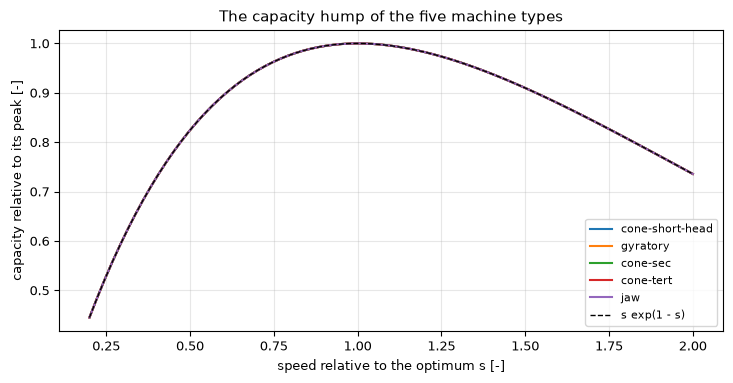

In [4]:
# Normalised capacity against normalised speed for the five machine types, at their own reference gap
s = np.linspace(0.2, 2.0, 80)
fig, ax = plt.subplots()
for machine, m in CAP.items():
    at_peak = throughput(machine, m.ref_gap_mm, 0.0, m.speed_opt)
    curve = [throughput(machine, m.ref_gap_mm, 0.0, v * m.speed_opt) / at_peak for v in s]
    ax.plot(s, curve, label=machine)
ax.plot(s, s * np.exp(1 - s), "k--", lw=1, label="s exp(1 - s)")
ax.set_xlabel("speed relative to the optimum s [-]")
ax.set_ylabel("capacity relative to its peak [-]")
ax.set_title("The capacity hump of the five machine types")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The five coloured lines lie under the dashed one: the machine types differ in scale and in where they peak, not in the shape of the hump. A reader can therefore move from one machine to another knowing the curve is the same, and the optimum speed is the one number per machine that matters. The figure shows capacity alone; it says nothing about what the operator pays at a speed other than the optimum.

**Step 3, the full response to speed.** Speed also enters the energy of the nip (notebook 01 of topic 03): a faster cone applies more energy per nip and breaks finer. The cell runs the whole engine on S01 at five speeds, from half to a little over one and a half times the optimum, and prints throughput, power and P80 for each. The figure draws the three as percentages of their value at the optimum, so that their different units share one axis.

In [5]:
# Run the engine at five speeds and print throughput, power and P80
speeds = (180, 270, 360, 450, 560)
runs = {v: evaluate(replace(op, speed_rpm=float(v))) for v in speeds}
for v, r in runs.items():
    print(f"{v} rpm: {r.throughput_tph:6.1f} t/h  {r.power_kw:6.1f} kW  P80 {r.p80:5.2f} mm  Ecs {r.specific_energy_kwh_t:.3f} kWh/t")

180 rpm:  530.2 t/h   219.2 kW  P80 30.04 mm  Ecs 0.509 kWh/t
270 rpm:  619.4 t/h   268.6 kW  P80 28.59 mm  Ecs 0.764 kWh/t
360 rpm:  643.2 t/h   287.4 kW  P80 27.70 mm  Ecs 1.018 kWh/t
450 rpm:  626.1 t/h   285.4 kW  P80 27.11 mm  Ecs 1.273 kWh/t
560 rpm:  574.0 t/h   264.0 kW  P80 26.85 mm  Ecs 1.584 kWh/t


The figure draws the three outputs on a finer grid of 39 speeds, each as a percentage of its value at the optimum.

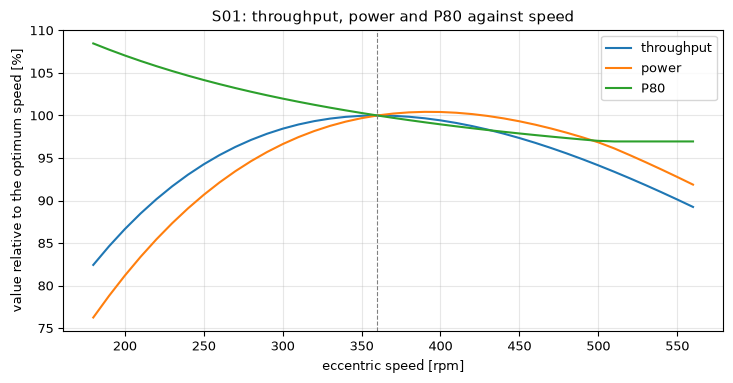

In [6]:
# Plot throughput, power and P80 as percentages of their value at the optimum speed
grid = np.linspace(180, 560, 39)
curves = [evaluate(replace(op, speed_rpm=float(v))) for v in grid]
reference = evaluate(op)
fig, ax = plt.subplots()
ax.plot(grid, [r.throughput_tph / reference.throughput_tph * 100 for r in curves], label="throughput")
ax.plot(grid, [r.power_kw / reference.power_kw * 100 for r in curves], label="power")
ax.plot(grid, [r.p80 / reference.p80 * 100 for r in curves], label="P80")
ax.axvline(optimal_speed(op.machine), color="grey", ls="--", lw=0.8)
ax.set_xlabel("eccentric speed [rpm]")
ax.set_ylabel("value relative to the optimum speed [%]")
ax.set_title("S01: throughput, power and P80 against speed")
ax.legend()
fig.tight_layout()
plt.show()

The three curves tell three stories. Throughput has its hump and peaks exactly at the dashed 360 rpm line; power follows a flatter curve with its maximum close to the optimum (287 kW at 360 rpm, 285 kW at 450 rpm), because a higher speed buys finer reduction while the tonnage is already falling; and P80 falls steadily with speed, since the energy per nip rises. So the speed that maximises tonnes is not the speed that gives the finest product, and the operator who wants the finest product pays in throughput. What the figure does not show is any limit of the machine: the engine does not model liner wear or vibration, and a speed well above the design range would not be allowed.

**Step 4, the nip angle.** A particle is gripped when the angle between the mantle and the bowl is below the grip limit $2\arctan\mu$, with the friction coefficient $\mu = 0.35$, about 38.6 degrees (Napier-Munn et al., 1996; https://search.worldcat.org/title/37081193). The engine's nip angle rises modestly with the setting, from about 22 degrees for a cone at its reference gap. The cell computes the angle across a range of settings against the limit.

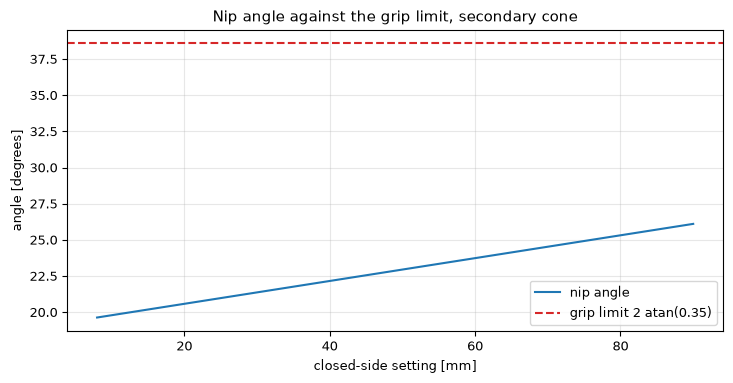

angle at S01: 21.53 | limit: 38.58 deg


In [7]:
# Nip angle of the secondary cone against the closed-side setting, with the grip limit
settings = np.linspace(8, 90, 42)
angles = [nip_angle(op.machine, css) for css in settings]
fig, ax = plt.subplots()
ax.plot(settings, angles, label="nip angle")
ax.axhline(nip_limit(), color="tab:red", ls="--", label="grip limit 2 atan(0.35)")
ax.set_xlabel("closed-side setting [mm]")
ax.set_ylabel("angle [degrees]")
ax.set_title("Nip angle against the grip limit, secondary cone")
ax.legend()
fig.tight_layout()
plt.show()
print("angle at S01:", round(nip_angle(op.machine, op.css_mm), 2), "| limit:", round(nip_limit(), 2), "deg")

The angle stays well under the limit over the whole range, at about 21.5 degrees for S01, so on this model a secondary cone never loses its grip: there is no setting at which the engine predicts that particles slip. The figure also says what is not modelled: the angle is a function of the setting alone, with no dependence on the particle shape, the liner wear or the moisture of the feed, which are what in practice makes a cone lose grip. The check is a sanity bound, not a predictor of slip.

## Results

**Answer:** the reference cone moves the most tonnes at its optimum speed of 360 rpm, 643.2 t/h, and loses capacity on both sides: 530.2 t/h at 180 rpm and 574.0 t/h at 560 rpm. Moving away from the optimum costs differently in each direction. Going faster raises the energy per nip from 1.018 to 1.584 kWh/t and brings P80 down from 27.70 to 26.85 mm, at a 10.8 percent loss of tonnage; going slower cuts the power from 287 to 219 kW and coarsens the product to 30.04 mm. The nip angle stays near 21.5 degrees against a limit of 38.58.

The first figure shows that the five machine types of the engine have the same hump, the second that capacity, power and size respond to speed in three different ways, and the third that the grip is never the constraint on this model. A validator would conclude that the speed that maximises tonnage is a property of the machine, and that picking a speed is a trade between tonnes, power and product size, whose terms the engine gives. These are reduced-form numbers: the absolute tonnages are illustrative per machine type, and only the real HP500 lane of topic 05 anchors them to measurements.

## Summary

Capacity is the product of a linear opening factor and a hump in speed that all machine types share. Speed moves three outputs in three different ways, so the best speed depends on what the plant is short of. The nip angle is a sanity bound, not a limit that binds. Notebook 02 takes up the setting and the throw and the Bond energy behind the power.

## References

- Evertsson, C. M. (2000), Cone crusher performance, doctoral thesis, Chalmers University of Technology. https://research.chalmers.se/en/publication/759
- Evertsson, C. M. (1999), Modelling of flow in cone crushers, Minerals Engineering 12(12), 1479-1499. https://doi.org/10.1016/S0892-6875(99)00136-3
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193